# 03 Features and preprocessing

**Purpose.** Decide which inputs the load forecast uses and how to treat gaps, outliers and solar negatives, using time-series cross-validation (never shuffled).

**Data.** `data/sim/` (dev scale, seed 7). The last 7 days are held out and not touched here.

**Outcome.** A results table that picks the feature set and preprocessing for `04`, and the feature code `silip_ml` must match.

In [1]:
import inspect

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from _data import HOLIDAYS, holdout_start, load_tables
from _features import LOAD_FEATURES, LOAD_PARAMS, load_features, same_slot_mean, to_grid
from _models import fit_load_model, load_table, save_result
from _style import COLORS, DIVERGING, label

tables = load_tables()
load, weather = tables["load"], tables["weather"]
holidays = HOLIDAYS
cutoff = holdout_start(load)
load = load[load["ts"] < cutoff]  # the held-out week stays unseen until 06
print(f"training data ends {cutoff:%Y-%m-%d}; holidays: {holidays}")

training data ends 2026-05-20; holidays: ['2026-04-02', '2026-04-03', '2026-04-04', '2026-04-09', '2026-05-01', '2026-06-12']


## The candidate features
The scoring job forecasts at 00:00 for the next 24 hours, so every input must be known by then. Each candidate is at least one day old:

| Feature | Meaning |
|---|---|
| `lag_1d`, `lag_2d`, `lag_7d` | load at the same 15-minute slot 1, 2 and 7 days ago |
| `same_slot_mean_3d`, `same_slot_mean_7d` | mean of that slot over the last 3 and 7 days, skipping missing ones |
| `hour`, `day_of_week`, `is_weekend`, `is_holiday` | calendar |

Gaps stay as missing values (`NaN`); LightGBM sends them down a learned branch. Here is the code, so it can be read next to `silip_ml/features.py` (which builds only the chosen features):

In [2]:
print(inspect.getsource(to_grid))
print(inspect.getsource(same_slot_mean))
print(inspect.getsource(load_features))

def to_grid(load: pd.DataFrame, column: str = "transformer_kw", until: pd.Timestamp | None = None) -> pd.DataFrame:
    """Wide table: one row per 15-minute interval, one column per transformer. Gaps become NaN."""
    wide = load.pivot(index="ts", columns="transformer_id", values=column).sort_index()
    end = wide.index[-1] if until is None else until
    return wide.reindex(pd.date_range(wide.index[0], end, freq="15min"))

def same_slot_mean(grid: pd.DataFrame, days: int) -> pd.DataFrame:
    """Mean of the same 15-minute slot over the last `days` days, skipping missing ones."""
    total, count = 0.0, 0.0
    for d in range(1, days + 1):
        past = grid.shift(d * STEPS_PER_DAY)
        total = total + past.fillna(0.0)
        count = count + past.notna().astype(float)
    return total / count.where(count > 0)

def load_features(grid: pd.DataFrame, holidays: list[str]) -> pd.DataFrame:
    """Long table of features per (transformer, ts) on the grid. NaN where history is missing.

In [3]:
table = load_table(load, holidays)
table = table.merge(weather[["ts", "heat_index_c"]], on="ts")
# An extra candidate, tested below: mean load over the 24 h that ended one day ago.
day_mean = to_grid(load).shift(96).rolling(96, min_periods=1).mean().stack(future_stack=True)
table["day_mean_1d"] = day_mean.reindex(pd.MultiIndex.from_frame(table[["ts", "transformer_id"]])).to_numpy()
table = table[table["ts"] >= table["ts"].min() + pd.Timedelta(days=7)]  # first week has no 7-day lag
print(f"{len(table):,} rows, {table['transformer_kw'].isna().mean():.1%} with a missing target")
table[LOAD_FEATURES + ["same_slot_mean_3d", "same_slot_mean_7d", "transformer_kw"]].describe().T.round(2)

205,632 rows, 0.9% with a missing target


,count,mean,std,min,25%,50%,75%,max
lag_1d,203790.0,26.77,19.36,-8.89,12.90,19.68,36.82,151.65
lag_2d,203787.0,26.54,19.09,-14.15,12.86,19.60,36.41,150.43
lag_7d,203768.0,25.77,17.84,-14.15,12.98,19.56,35.02,134.42
hour,205632.0,11.88,6.93,0.00,5.94,11.88,17.81,23.75
day_of_week,205632.0,3.00,2.00,0.00,1.00,3.00,5.00,6.00
is_weekend,205632.0,0.29,0.45,0.00,0.00,0.00,1.00,1.00
is_holiday,205632.0,0.05,0.21,0.00,0.00,0.00,0.00,1.00
same_slot_mean_3d,205632.0,26.53,17.31,-6.83,14.48,21.28,34.31,140.38
same_slot_mean_7d,205632.0,26.14,15.43,0.70,15.72,22.02,31.78,136.00
transformer_kw,203808.0,27.00,19.66,-8.89,12.93,19.74,37.25,156.25


## How do the features relate to the target and to each other?

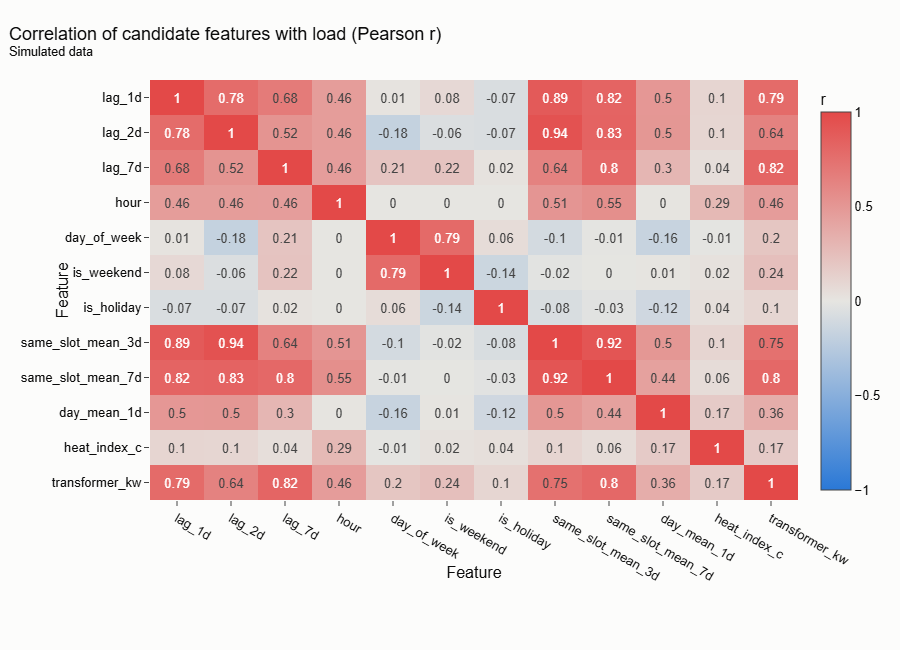

In [4]:
corr_columns = LOAD_FEATURES + ["same_slot_mean_3d", "same_slot_mean_7d", "day_mean_1d", "heat_index_c", "transformer_kw"]
corr = table[corr_columns].corr()
fig = go.Figure(go.Heatmap(z=corr.to_numpy(), x=corr_columns, y=corr_columns, colorscale=DIVERGING, zmin=-1, zmax=1, text=corr.round(2).to_numpy(), texttemplate="%{text}", colorbar={"title": "r"}))
fig.update_yaxes(autorange="reversed")
fig.update_layout(height=650, margin={"l": 150, "b": 150})
label(fig, "Correlation of candidate features with load (Pearson r)", "Feature", "Feature").show()

Takeaway: the lags and same-slot means all track load closely and each other too; the calendar features carry the daily shape. Heat index matters, but it is a same-day value.

## Time-series cross-validation
Three folds, each validating on one week and training on everything before it. Error is mean absolute error in kW over intervals with a known target.

In [5]:
FOLDS = [cutoff - pd.Timedelta(days=7 * k) for k in (3, 2, 1)]
QUICK = {"n_estimators": 200, "learning_rate": 0.05, "num_leaves": 31, "min_child_samples": 20}


def cv_mae(frame: pd.DataFrame, features: list[str], target_fix=None, params=QUICK) -> list[float]:
    """MAE per fold; `target_fix` changes the training target only (validation is always raw)."""
    maes = []
    for start in FOLDS:
        train = frame[frame["ts"] < start]
        valid = frame[(frame["ts"] >= start) & (frame["ts"] < start + pd.Timedelta(days=7))].dropna(subset=["transformer_kw"])
        if target_fix is not None:
            train = train.assign(transformer_kw=target_fix(train))
        model = fit_load_model(train, params, features)
        maes.append(float(np.abs(model.predict(valid[features].to_numpy()) - valid["transformer_kw"]).mean()))
    return maes


def naive_mae(frame: pd.DataFrame) -> list[float]:
    maes = []
    for start in FOLDS:
        valid = frame[(frame["ts"] >= start) & (frame["ts"] < start + pd.Timedelta(days=7))].dropna(subset=["transformer_kw"])
        guess = valid["lag_7d"].fillna(valid["same_slot_mean_7d"])
        maes.append(float(np.abs(guess - valid["transformer_kw"]).mean()))
    return maes


results = []


def record(group: str, option: str, maes: list[float], usable: str = "yes") -> None:
    results.append({"question": group, "option": option, **{f"fold {i + 1}": m for i, m in enumerate(maes)}, "mean MAE (kW)": float(np.mean(maes)), "usable at scoring time": usable})


record("baseline", "seasonal naive (same slot last week)", naive_mae(table))

### Which feature set?

In [6]:
LAGS = ["lag_1d", "lag_2d", "lag_7d"]
CALENDAR = ["hour", "day_of_week", "is_weekend", "is_holiday"]
record("features", "lags only", cv_mae(table, LAGS))
record("features", "lags + calendar (chosen)", cv_mae(table, LOAD_FEATURES))
record("features", "chosen + same-slot means (3 and 7 days)", cv_mae(table, LOAD_FEATURES + ["same_slot_mean_3d", "same_slot_mean_7d"]))
record("features", "chosen + rolling 1-day mean", cv_mae(table, LOAD_FEATURES + ["day_mean_1d"]))
record("features", "chosen + heat index of the forecast day", cv_mae(table, LOAD_FEATURES + ["heat_index_c"]), usable="no: needs a weather forecast feed")
pd.DataFrame(results).round(3)

,question,option,fold 1,fold 2,fold 3,mean MAE (kW),usable at scoring time
0,baseline,seasonal naive (same slot last week),9.452,9.675,6.710,8.612,yes
1,features,lags only,8.374,6.821,5.605,6.934,yes
2,features,lags + calendar (chosen),6.561,5.586,3.848,5.332,yes
3,features,chosen + same-slot means (3 and 7 days),7.211,6.000,3.798,5.670,yes
4,features,chosen + rolling 1-day mean,6.837,5.722,3.729,5.429,yes
5,features,chosen + heat index of the forecast day,4.597,4.251,3.204,4.017,no: needs a weather forecast feed


Takeaway: the calendar cuts the error most. Same-slot means and a rolling 1-day mean repeat what the lags already say and do not help on average, so they stay out (fewer features to keep in step with `silip_ml`). Knowing the day's heat index would cut error the most, but the scoring job has no weather forecast today, so it is left out (and noted for the api handoff).

### Day-ahead weather (ADR 0006)
The scoring job now has a weather feed: Open-Meteo hourly forecasts, issued before the run. The simulator writes the same shape (`weather_forecast_hourly.csv`): forecasts issued daily at 00:00 for 72 h, equal to the true weather plus error, and the observed hours as `archive`. Training uses only the forecasts, never the true weather that generated the load. Three inputs, each read from forecasts issued by 00:00 of the forecast day:

| Feature | Meaning |
|---|---|
| `hi_fcst_c` | forecast heat index at the target hour (NOAA formula, `_weather.heat_index_c`) |
| `hi_fcst_minus_lag1d_c` | that forecast minus the observed heat index 24 h earlier, the hour `lag_1d` saw |
| `rain_fcst_mm` | forecast rain at the target hour |

Each transformer reads its weather cell (`_weather.cell_id`, 0.1° grid). The simulator has one regional weather series, so every cell carries the same values here.

In [7]:
from _features import LOAD_FEATURES_WEATHER, WEATHER_FEATURES, add_weather_features

forecast_weather, transformers = tables["weather_forecast"], tables["transformers"]
wtable = add_weather_features(table, forecast_weather, transformers)
hot_days = set(weather.loc[weather["weather"] == "hot_spell", "ts"].dt.normalize())


def hot_mae(frame: pd.DataFrame, features: list[str]) -> list[float]:
    """MAE per fold on hot-spell days only (the simulator's label, used for grouping only)."""
    maes = []
    for start in FOLDS:
        train = frame[frame["ts"] < start]
        valid = frame[(frame["ts"] >= start) & (frame["ts"] < start + pd.Timedelta(days=7))].dropna(subset=["transformer_kw"])
        hot = valid["ts"].dt.normalize().isin(hot_days).to_numpy()
        error = np.abs(fit_load_model(train, QUICK, features).predict(valid[features].to_numpy()) - valid["transformer_kw"].to_numpy())
        maes.append(float(error[hot].mean()) if hot.any() else float("nan"))
    return maes


record("weather", "chosen + day-ahead weather forecast (lightgbm_weather)", cv_mae(wtable, LOAD_FEATURES_WEATHER))
record("weather", "chosen + forecast heat index and rain only", cv_mae(wtable, LOAD_FEATURES + ["hi_fcst_c", "rain_fcst_mm"]))
hot = pd.DataFrame({"chosen": hot_mae(wtable, LOAD_FEATURES), "chosen + weather": hot_mae(wtable, LOAD_FEATURES_WEATHER)}, index=[f"fold {i + 1}" for i in range(3)])
display(pd.DataFrame(results).round(3).tail(2))
hot.round(3).rename_axis("MAE on hot-spell days (kW)")

,question,option,fold 1,fold 2,fold 3,mean MAE (kW),usable at scoring time
6,weather,chosen + day-ahead weather forecast (lightgbm_...,6.260,6.992,4.416,5.889,yes
7,weather,chosen + forecast heat index and rain only,5.565,6.594,3.782,5.313,yes


,chosen,chosen + weather
MAE on hot-spell days (kW),,
fold 1,6.386,6.549
fold 2,3.238,4.370
fold 3,3.670,3.858


daily max heat index: forecast error mean +0.78 °C, MAE 2.97 °C, worst 9.1 °C


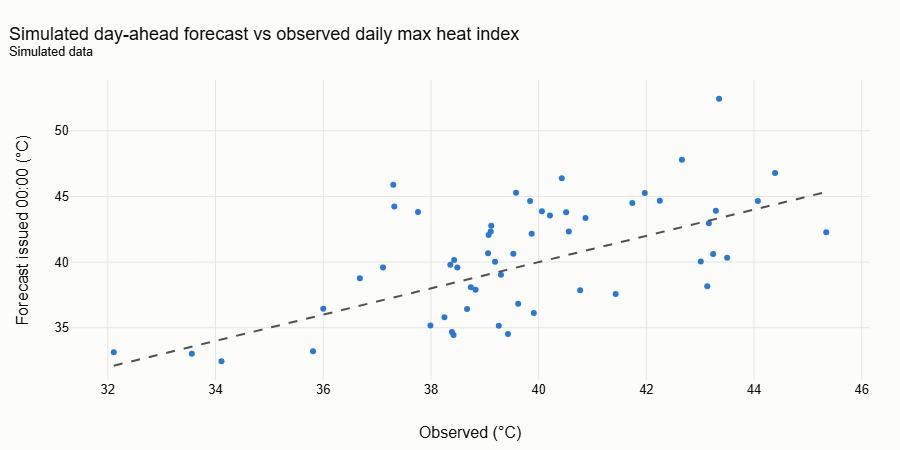

In [8]:
# How far off is the simulated day-ahead forecast? Daily maximum heat index, forecast (issued 00:00 that day) vs observed.
fw = forecast_weather[forecast_weather["cell_id"] == forecast_weather["cell_id"].iloc[0]]
same_day = fw[(fw["kind"] == "forecast") & (fw["ts"].dt.normalize() == fw["issued_at"])]
observed = fw[fw["kind"] == "archive"]
daily = pd.DataFrame({
    "forecast": same_day.groupby(same_day["ts"].dt.normalize())["heat_index_c"].max(),
    "observed": observed.groupby(observed["ts"].dt.normalize())["heat_index_c"].max(),
}).dropna()
daily["error"] = daily["forecast"] - daily["observed"]
print(f"daily max heat index: forecast error mean {daily['error'].mean():+.2f} °C, MAE {daily['error'].abs().mean():.2f} °C, worst {daily['error'].abs().max():.1f} °C")
fig = px.scatter(daily.reset_index(), x="observed", y="forecast", color_discrete_sequence=COLORS[:1])
fig.add_shape(type="line", x0=daily["observed"].min(), y0=daily["observed"].min(), x1=daily["observed"].max(), y1=daily["observed"].max(), line={"dash": "dash", "color": "#52514e"})
label(fig, "Simulated day-ahead forecast vs observed daily max heat index", "Observed (°C)", "Forecast issued 00:00 (°C)").show()

Takeaway: with the simulated day-ahead forecast, the three weather inputs do not help on average (5.89 vs 5.33 kW over the three folds) and are worse on hot-spell days in every fold, while the true heat index of the day would cut error to 4.02 kW. The gap is the forecast itself: it misses the daily maximum heat index by 3.0 °C on average and by up to 9 °C (`weather.forecast_error_sd_c` `[VERIFY]` against Open-Meteo's skill for Metro Manila). The inputs still go to `04` and `06`, which decide on the validation and held-out weeks. Part of any gain on simulated data exists by construction: the simulator drives load with the same heat index the forecast is built from.

### How to handle gaps?
Missing intervals come from outages. Options: keep them as missing (LightGBM handles `NaN`), fill forward before building features, or drop training rows with any missing input.

In [9]:
filled = load_table(
    to_grid(load).ffill().stack(future_stack=True).rename("transformer_kw").reset_index().rename(columns={"level_0": "ts"}),
    holidays,
)
filled = filled[filled["ts"].isin(table["ts"])].drop(columns="transformer_kw").merge(table[["transformer_id", "ts", "transformer_kw"]], on=["transformer_id", "ts"])
record("gaps", "keep as missing (chosen)", cv_mae(table, LOAD_FEATURES))
record("gaps", "fill forward", cv_mae(filled, LOAD_FEATURES))
record("gaps", "drop rows with a missing input", cv_mae(table.dropna(subset=LOAD_FEATURES), LOAD_FEATURES))
pd.DataFrame(results[-3:]).round(3)

,question,option,fold 1,fold 2,fold 3,mean MAE (kW),usable at scoring time
0,gaps,keep as missing (chosen),6.561,5.586,3.848,5.332,yes
1,gaps,fill forward,6.820,5.323,3.854,5.332,yes
2,gaps,drop rows with a missing input,6.540,5.827,3.773,5.380,yes


Takeaway: the three are close. Keeping gaps as missing is the simplest at inference (no fill rule to copy) and does at least as well.

### Outliers and solar negatives
Very high intervals are real (overloads are what SILIP looks for), and negative ones are real too (solar export). Clipping either changes what the model learns.

In [10]:
high = table.groupby("transformer_id")["transformer_kw"].transform(lambda s: s.quantile(0.999))
record("outliers", "no clipping (chosen)", cv_mae(table, LOAD_FEATURES))
record("outliers", "clip target at each transformer's 99.9th percentile", cv_mae(table, LOAD_FEATURES, lambda t: t["transformer_kw"].clip(upper=high.loc[t.index])))
record("solar", "clip negative target to 0", cv_mae(table, LOAD_FEATURES, lambda t: t["transformer_kw"].clip(lower=0)))
pd.DataFrame(results[-3:]).round(3)

,question,option,fold 1,fold 2,fold 3,mean MAE (kW),usable at scoring time
0,outliers,no clipping (chosen),6.561,5.586,3.848,5.332,yes
1,outliers,clip target at each transformer's 99.9th perce...,6.561,5.597,3.856,5.338,yes
2,solar,clip negative target to 0,6.596,5.670,3.856,5.374,yes


Takeaway: clipping does not help, and clipping peaks would hide the overloads the risk model needs. Keep the target as measured.

## Which features does the model lean on?

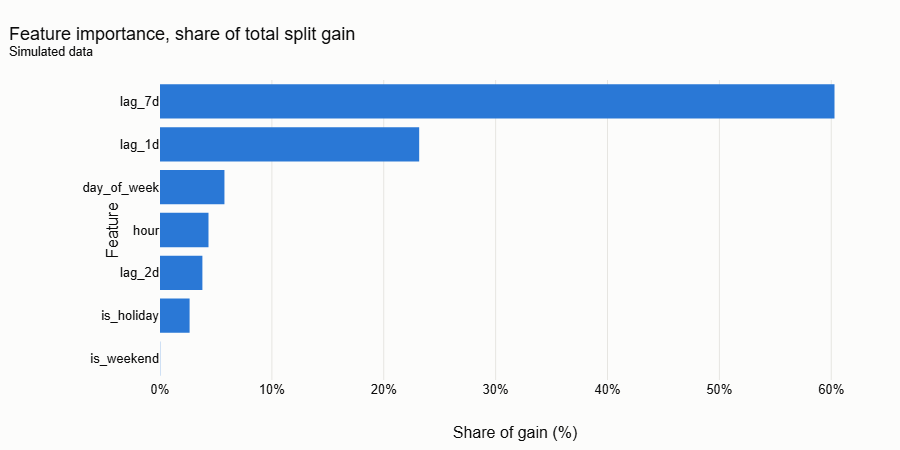

In [11]:
final_train = table[table["ts"] < FOLDS[-1]]
model = fit_load_model(final_train, QUICK)
importance = pd.DataFrame({"feature": LOAD_FEATURES, "gain": model.booster_.feature_importance("gain")})
importance["share"] = importance["gain"] / importance["gain"].sum()
fig = px.bar(importance.sort_values("share"), x="share", y="feature", orientation="h", color_discrete_sequence=COLORS[:1])
fig.update_xaxes(tickformat=".0%")
fig.update_layout(margin={"l": 160})
label(fig, "Feature importance, share of total split gain", "Share of gain (%)", "Feature").show()

Takeaway: the lags carry most of the gain and the hour of day shapes it; the holiday flag matters on few days, so its share is small.

### Gain with weather
The same split-gain view for `lightgbm_weather` (lags, calendar and the three weather inputs), trained on the same weeks.

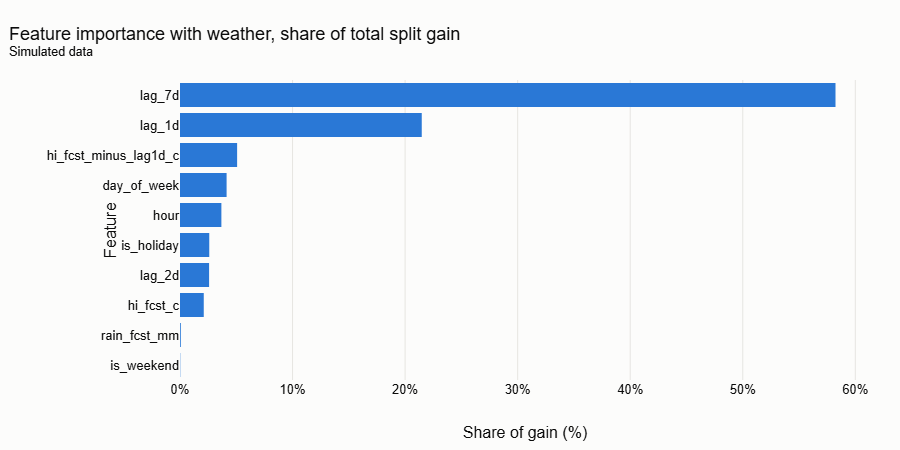

,feature,gain,share
2,lag_7d,3.355837e+08,0.582
0,lag_1d,1.237650e+08,0.215
8,hi_fcst_minus_lag1d_c,2.924288e+07,0.051
4,day_of_week,2.385824e+07,0.041
3,hour,2.118255e+07,0.037
6,is_holiday,1.498094e+07,0.026
1,lag_2d,1.489417e+07,0.026
7,hi_fcst_c,1.216513e+07,0.021
9,rain_fcst_mm,4.121923e+05,0.001
5,is_weekend,1.345156e+05,0.000


In [12]:
wmodel = fit_load_model(wtable[wtable["ts"] < FOLDS[-1]], QUICK, LOAD_FEATURES_WEATHER)
wimportance = pd.DataFrame({"feature": LOAD_FEATURES_WEATHER, "gain": wmodel.booster_.feature_importance("gain")})
wimportance["share"] = wimportance["gain"] / wimportance["gain"].sum()
fig = px.bar(wimportance.sort_values("share"), x="share", y="feature", orientation="h", color_discrete_sequence=COLORS[:1])
fig.update_xaxes(tickformat=".0%")
fig.update_layout(margin={"l": 180})
label(fig, "Feature importance with weather, share of total split gain", "Share of gain (%)", "Feature").show()
wimportance.sort_values("share", ascending=False).round(3)

## Results table

In [13]:
summary = pd.DataFrame(results).round(3)
save_result("03_preprocessing", {"folds": [str(f.date()) for f in FOLDS], "results": summary.to_dict("records"), "chosen_features": LOAD_FEATURES, "weather_features": WEATHER_FEATURES, "weather_gain_share": wimportance.set_index("feature")["share"].round(4).to_dict(), "feature_params": LOAD_PARAMS})
summary

,question,option,fold 1,fold 2,fold 3,mean MAE (kW),usable at scoring time
0,baseline,seasonal naive (same slot last week),9.452,9.675,6.710,8.612,yes
1,features,lags only,8.374,6.821,5.605,6.934,yes
2,features,lags + calendar (chosen),6.561,5.586,3.848,5.332,yes
3,features,chosen + same-slot means (3 and 7 days),7.211,6.000,3.798,5.670,yes
4,features,chosen + rolling 1-day mean,6.837,5.722,3.729,5.429,yes
5,features,chosen + heat index of the forecast day,4.597,4.251,3.204,4.017,no: needs a weather forecast feed
6,weather,chosen + day-ahead weather forecast (lightgbm_...,6.260,6.992,4.416,5.889,yes
7,weather,chosen + forecast heat index and rain only,5.565,6.594,3.782,5.313,yes
8,gaps,keep as missing (chosen),6.561,5.586,3.848,5.332,yes
9,gaps,fill forward,6.820,5.323,3.854,5.332,yes


**Outcome.** Use `LOAD_FEATURES` with gaps kept as missing and no clipping. Every option beats the seasonal naive baseline. A weather forecast is the biggest gain left on the table only if it is accurate: with the simulated forecast's error, `LOAD_FEATURES_WEATHER` does not beat `LOAD_FEATURES` in cross-validation. `04` tunes both.